# Maintenance of Equipments

# Table of Contents

- 1. Data Overview
  - [1.1. Importing libraries](#scrollTo=b22202eb)
  -	[1.2. Reading csv file](#scrollTo=6dd31304)
- 2. Data Preprocessing
  - [2.1. Checking for nulls (missing values) and uniques](#scrollTo=81e71cf1)
  - [2.2. Missing values](#scrollTo=7bb93063)
  - [2.3. Checking for duplicate rows](#scrollTo=d4ab1b59)
  - [2.4. Dropping unnecessary columns (UDI and Product ID)](#scrollTo=41a631f3)
  - [2.5. Identifying categorical columns](#scrollTo=55aa783a)
  - [2.6. Value counts for categorical columns](#scrollTo=25665445)
  - [2.7. Identifying faulty machines with 'Target' value 1](#scrollTo=efe9e8a8)
  - [2.8. Removing rows with 'No Failure' in faulty machines](#scrollTo=2fb1d4a6)
  - [2.9. Identifying non-faulty machines with 'Target' value 0](#scrollTo=9aeb32ad)
  - [2.10. Removing rows with 'Random Failures' in non-faulty machines](#scrollTo=0bd69ad7)
  - [2.11. Replacing infinite values with NaN](#scrollTo=02184796)
  - [2.12. Encoding and mapping categorical variables](#scrollTo=010ea37d)
  - [2.13. Rename the variables](#scrollTo=CVpkGl8fzp5A&line=1&uniqifier=1)
- 3. Exploratory Data Analysis
  - [3.1. Describing the variables](#scrollTo=64432b19)
  - [3.2. Skewness](#scrollTo=e84f3a33)
  - [3.3. Box plot](#scrollTo=e89961ab)
  - [3.4. Individual box plot](#scrollTo=120e16cc)
  - [3.5. Histograms](#scrollTo=17cc1339)
  - [3.5. Pairplot visualization](#scrollTo=e8c1fc9c)
- 4. Correlation Analysis
  - [4.1. Correlation matrix](#scrollTo=bb376c90)
- 5. Predictive Modeling
  - [5.1. Determinating X and Y](#scrollTo=f06c3299&line=1&uniqifier=1)
  - [5.2. Smote (y class balanced)](#scrollTo=6230e1a8&line=19&uniqifier=1)
  - [5.3. Gridseach](#scrollTo=a97328cb&line=1&uniqifier=1)
  - [5.4. K – Fold Cross Validation](#scrollTo=6230e1a8&line=1&uniqifier=1)
  - [5.5. Train – Test predictive modelling](#scrollTo=6230e1a8&line=32&uniqifier=1)
- 6. Model Evaluation
  - [6.1. Metrics indicators](#scrollTo=6230e1a8&line=61&uniqifier=1)
  

## Importing libraries

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.io as pio
import seaborn as sns
import matplotlib.pyplot as plt
pio.templates.default = 'plotly_white'
from sklearn import metrics
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix
from sklearn import tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV
from imblearn.over_sampling import SMOTE
from collections import Counter

## Reading csv file

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
df=pd.read_csv("/content/drive/My Drive/Colab Notebooks/predictive_maintenance.csv")

In [4]:
df

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure
...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,No Failure
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,No Failure
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,No Failure
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,No Failure


## Describing the variables

In [5]:
df.shape

(10000, 10)

In [6]:
df.tail(5)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,No Failure
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,No Failure
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,No Failure
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,No Failure
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,No Failure


In [7]:
df.head(10)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure
5,6,M14865,M,298.1,308.6,1425,41.9,11,0,No Failure
6,7,L47186,L,298.1,308.6,1558,42.4,14,0,No Failure
7,8,L47187,L,298.1,308.6,1527,40.2,16,0,No Failure
8,9,M14868,M,298.3,308.7,1667,28.6,18,0,No Failure
9,10,M14869,M,298.5,309.0,1741,28.0,21,0,No Failure


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB


In [9]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000


## Checking for nulls and uniques

In [10]:
df['Target'].unique()

array([0, 1])

In [11]:
df['Failure Type'].unique()

array(['No Failure', 'Power Failure', 'Tool Wear Failure',
       'Overstrain Failure', 'Random Failures',
       'Heat Dissipation Failure'], dtype=object)

In [12]:
df['Air temperature [K]'].unique()

array([298.1, 298.2, 298.3, 298.5, 298.4, 298.6, 298.7, 298.8, 298.9,
       299. , 299.1, 298. , 297.9, 297.8, 297.7, 297.6, 297.5, 297.4,
       297.3, 297.2, 297.1, 297. , 296.9, 296.8, 296.7, 296.6, 296.5,
       296.3, 296.4, 296.2, 296.1, 296. , 295.9, 295.8, 295.7, 295.6,
       295.5, 295.4, 295.3, 299.2, 299.3, 299.5, 299.4, 299.6, 299.7,
       299.8, 299.9, 300. , 300.1, 300.2, 300.3, 300.4, 300.5, 300.6,
       300.7, 300.8, 300.9, 301. , 301.1, 301.2, 301.3, 301.4, 301.5,
       301.6, 301.7, 301.8, 301.9, 302. , 302.1, 302.2, 302.3, 302.4,
       302.5, 302.6, 302.7, 302.8, 302.9, 303. , 303.1, 303.2, 303.3,
       303.4, 303.5, 303.6, 303.7, 303.8, 303.9, 304. , 304.1, 304.2,
       304.3, 304.4, 304.5])

In [13]:
df['Type'].unique()

array(['M', 'L', 'H'], dtype=object)

In [14]:
columns_to_check = ['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target', 'Failure Type']

for col in columns_to_check:
    print(df[df[col].isna()])

Empty DataFrame
Columns: [UDI, Product ID, Type, Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min], Target, Failure Type]
Index: []
Empty DataFrame
Columns: [UDI, Product ID, Type, Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min], Target, Failure Type]
Index: []
Empty DataFrame
Columns: [UDI, Product ID, Type, Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min], Target, Failure Type]
Index: []
Empty DataFrame
Columns: [UDI, Product ID, Type, Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min], Target, Failure Type]
Index: []
Empty DataFrame
Columns: [UDI, Product ID, Type, Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min], Target, Failure Type]
Index: []
Empty DataFrame
Columns: [UDI, Product ID, Type, Air temperature [K], Process temperature [K], 

## Missing values

In [15]:
null_df = df.isnull().sum() * 100/len(df)

info_df = pd.DataFrame({'qtd_missing': df.isnull().sum(),
                       'percent_missing': null_df,
                       'dtype': df.dtypes}
                      ).reset_index().rename(columns={'index': 'column'})
info_df

,column,qtd_missing,percent_missing,dtype
0,UDI,0,0.0,int64
1,Product ID,0,0.0,object
2,Type,0,0.0,object
3,Air temperature [K],0,0.0,float64
4,Process temperature [K],0,0.0,float64
5,Rotational speed [rpm],0,0.0,int64
6,Torque [Nm],0,0.0,float64
7,Tool wear [min],0,0.0,int64
8,Target,0,0.0,int64
9,Failure Type,0,0.0,object


## Checking for duplicate rows

In [16]:
df.duplicated().sum()

np.int64(0)

## Dropping unnecessary columns (UDI and Product ID)

In [17]:
df.drop(['UDI', 'Product ID'], axis=1, inplace=True)

In [19]:
df.head(10)

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,M,298.1,308.6,1551,42.8,0,0,No Failure
1,L,298.2,308.7,1408,46.3,3,0,No Failure
2,L,298.1,308.5,1498,49.4,5,0,No Failure
3,L,298.2,308.6,1433,39.5,7,0,No Failure
4,L,298.2,308.7,1408,40.0,9,0,No Failure
5,M,298.1,308.6,1425,41.9,11,0,No Failure
6,L,298.1,308.6,1558,42.4,14,0,No Failure
7,L,298.1,308.6,1527,40.2,16,0,No Failure
8,M,298.3,308.7,1667,28.6,18,0,No Failure
9,M,298.5,309.0,1741,28.0,21,0,No Failure


## Skewness

Its values allows us to understand how data is distributed in relation to a symmetric or normal distribution.

Skewness ≈ 0: The distribution is approximately symmetrical. This indicates that the data is not biased toward the left or the right.

Skewness > 0 (positive skewness): The tail of the distribution is longer towards the right.

Skewness < 0 (negative skewness): The tail of the distribution is longer towards the left.

In [20]:
df.skew(axis=0, skipna=True, numeric_only=True)

,0
Air temperature [K],0.114274
Process temperature [K],0.015027
Rotational speed [rpm],1.993171
Torque [Nm],-0.009517
Tool wear [min],0.027292
Target,5.151852


## Identifying categorical columns

In [21]:
cat_cols = df.select_dtypes(include='object').columns.tolist()
print(cat_cols)

['Type', 'Failure Type']


## Value counts for categorical columns

In [22]:
for col in cat_cols:
    print(df[col].value_counts())

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64
Failure Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64


## Identifying faulty machines with 'Target' value 1

In [23]:
df_f = df[df.Target == 1]
df_f['Failure Type'].value_counts()

,count
Failure Type,
Heat Dissipation Failure,112
Power Failure,95
Overstrain Failure,78
Tool Wear Failure,45
No Failure,9


## Removing rows with 'No Failure' in faulty machines

In [24]:
idx = df_f[df_f['Failure Type'] == 'No Failure'].index
df.drop(idx, axis=0, inplace=True)

## Identifying non-faulty machines with 'Target' value 0

In [25]:
df_f = df[df.Target == 0]
df_f['Failure Type'].value_counts()

,count
Failure Type,
No Failure,9643
Random Failures,18


## Removing rows with 'Random Failures' in non-faulty machines

In [28]:
idx = df_f[df_f['Failure Type'] == 'Random Failures'].index
df.drop(idx, axis=0, inplace=True)

KeyError: '[1221, 1302, 1748, 2072, 2559, 3065, 3452, 5471, 5489, 5495, 5509, 5553, 5639, 6091, 6913, 6960, 7488, 7868] not found in axis'

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9973 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Type                     9973 non-null   object 
 1   Air temperature [K]      9973 non-null   float64
 2   Process temperature [K]  9973 non-null   float64
 3   Rotational speed [rpm]   9973 non-null   int64  
 4   Torque [Nm]              9973 non-null   float64
 5   Tool wear [min]          9973 non-null   int64  
 6   Target                   9973 non-null   int64  
 7   Failure Type             9973 non-null   object 
dtypes: float64(3), int64(3), object(2)
memory usage: 701.2+ KB


## Replacing infinite values with NaN

In [29]:
df.replace([np.inf, -np.inf], np.nan, inplace=True)

In [34]:
columns_to_check = ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target', 'Failure Type']

for col in columns_to_check:
    print(df[df[col].isna()])

Empty DataFrame
Columns: [Type, Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min], Target, Failure Type]
Index: []
Empty DataFrame
Columns: [Type, Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min], Target, Failure Type]
Index: []
Empty DataFrame
Columns: [Type, Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min], Target, Failure Type]
Index: []
Empty DataFrame
Columns: [Type, Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min], Target, Failure Type]
Index: []
Empty DataFrame
Columns: [Type, Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min], Target, Failure Type]
Index: []
Empty DataFrame
Columns: [Type, Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min], Target, Failure Type]
Index: []
Empty DataFrame


## Correlation matrix

In [30]:
df.corr(method='pearson', numeric_only=True)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
Air temperature [K],1.000000,0.876068,0.023332,-0.014553,0.014370,0.083066
Process temperature [K],0.876068,1.000000,0.020200,-0.015275,0.013970,0.035997
Rotational speed [rpm],0.023332,0.020200,1.000000,-0.875069,-0.000110,-0.044042
Torque [Nm],-0.014553,-0.015275,-0.875069,1.000000,-0.002552,0.193420
Tool wear [min],0.014370,0.013970,-0.000110,-0.002552,1.000000,0.106337
Target,0.083066,0.035997,-0.044042,0.193420,0.106337,1.000000


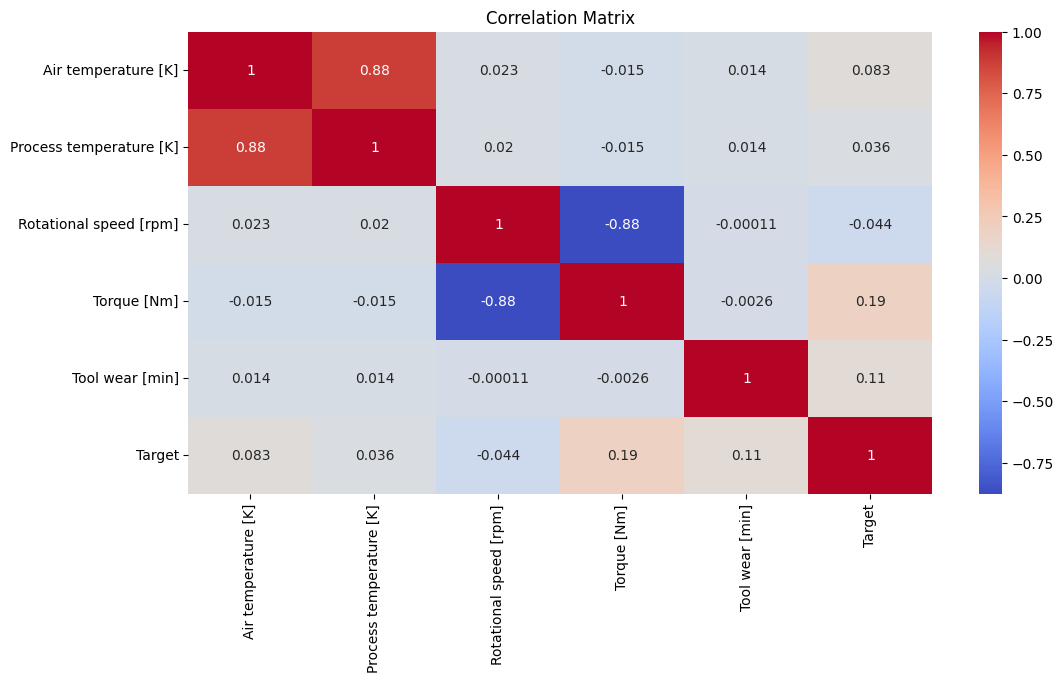

In [31]:
numeric_df = df.select_dtypes(include=[np.number])
numeric_df.replace([np.inf, -np.inf], np.nan, inplace=True)

plt.figure(figsize=(12, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

## Box plot

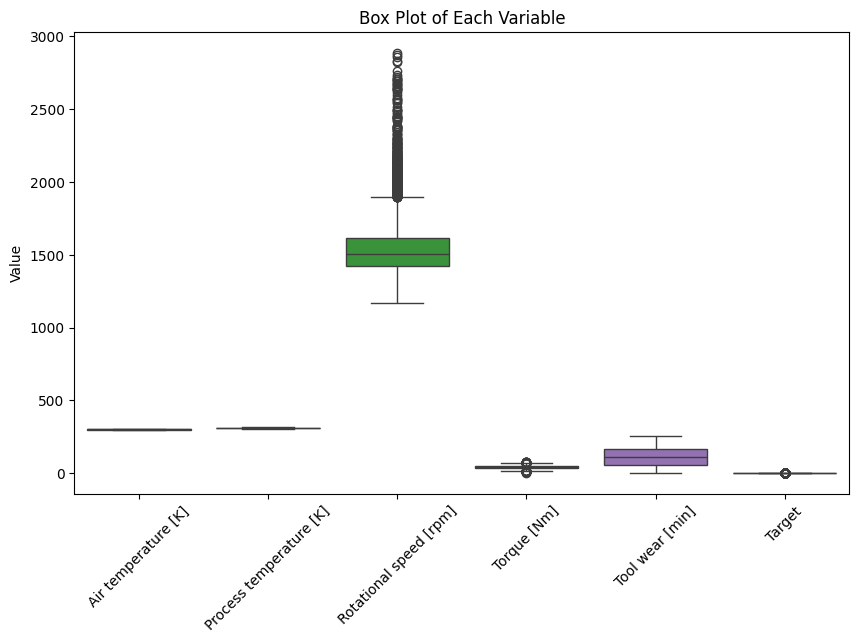

In [33]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df)
plt.title("Box Plot of Each Variable")
plt.xticks(rotation=45)
plt.ylabel("Value")
plt.show()

### Individual box plot

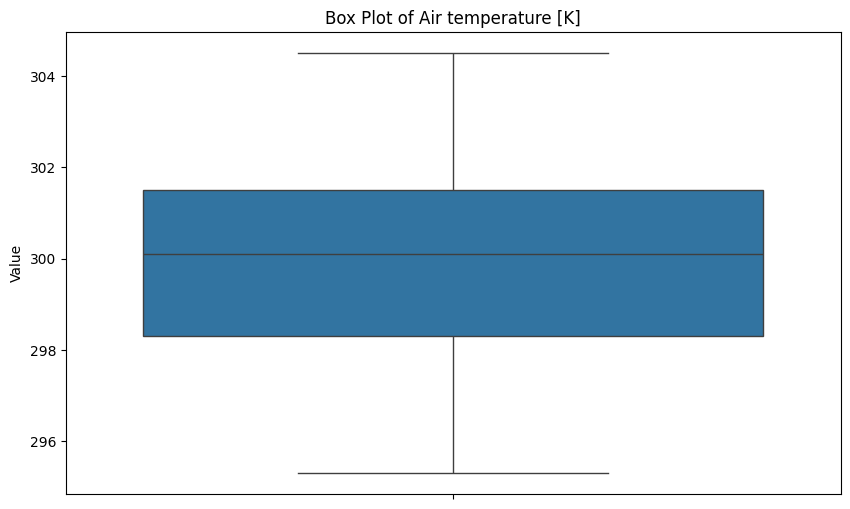

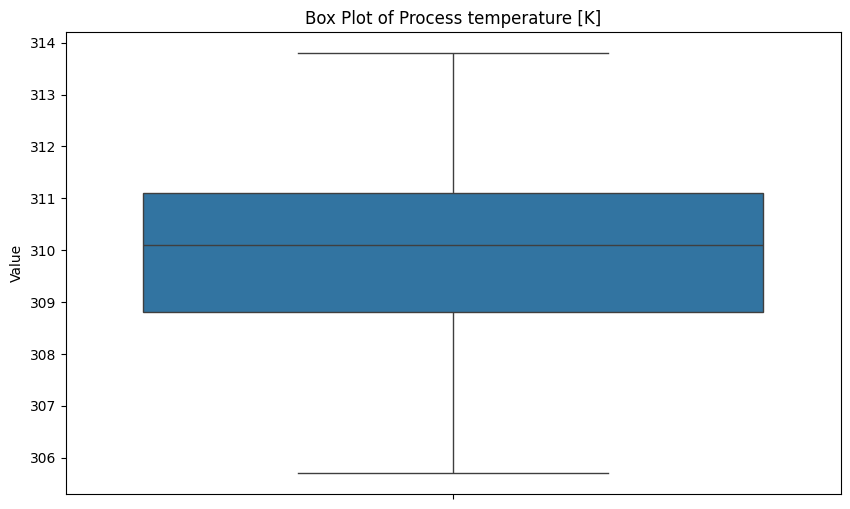

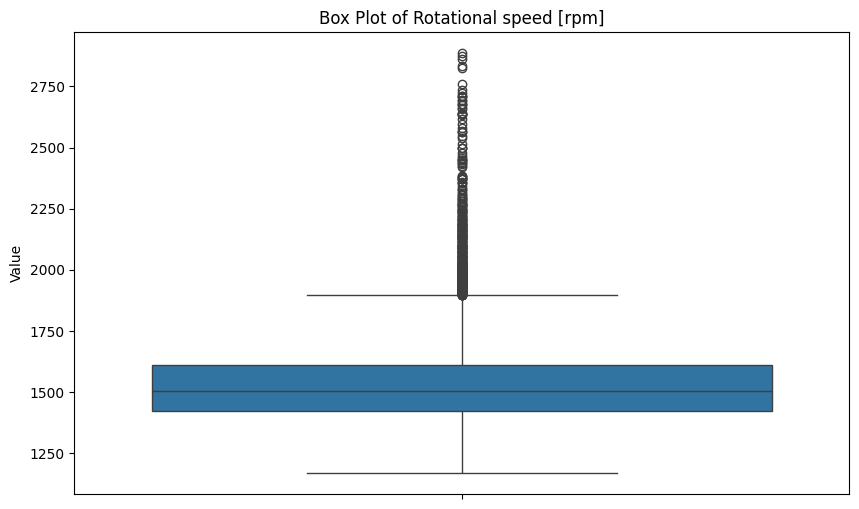

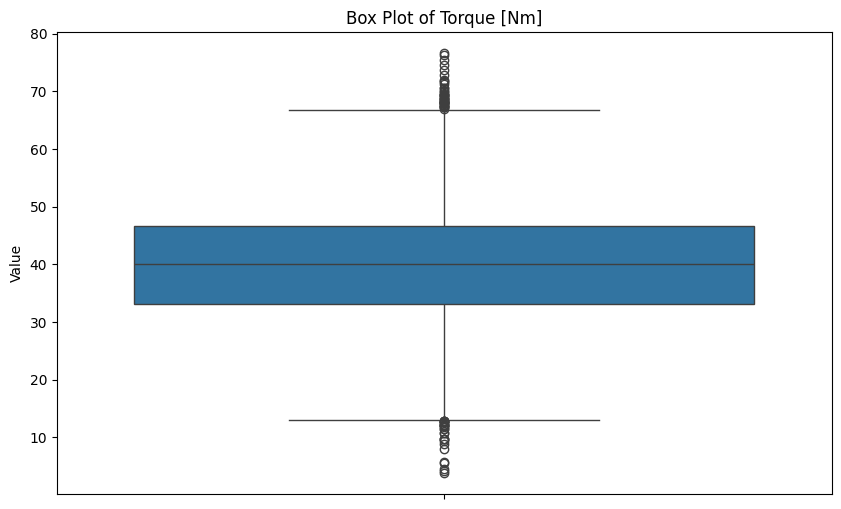

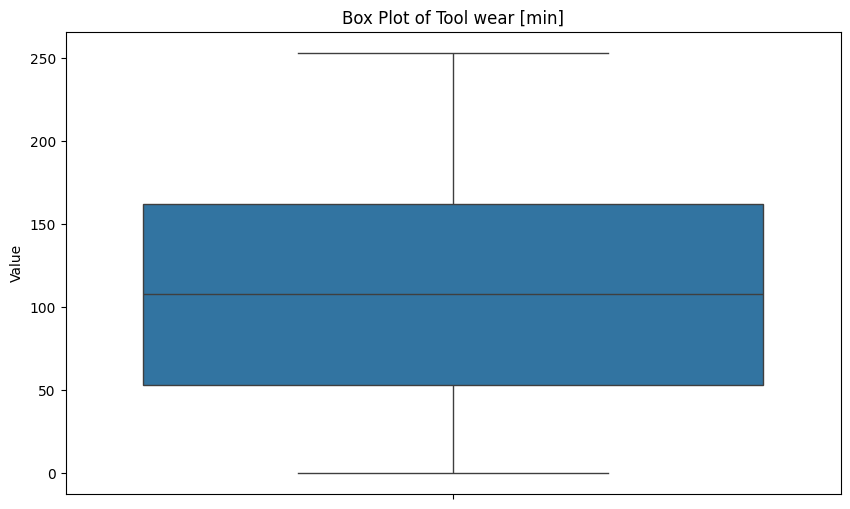

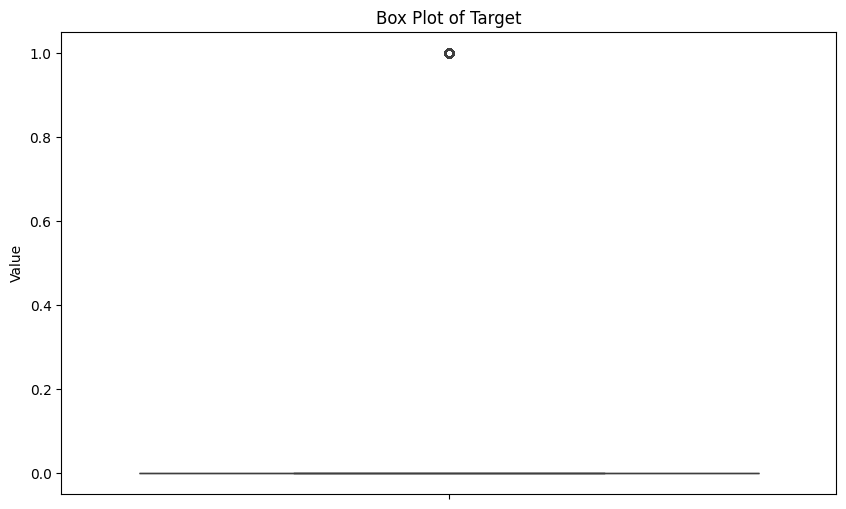

In [34]:
num_cols = df.select_dtypes(include='number').columns

for column in num_cols:
    plt.figure(figsize=(10, 6))
    sns.boxplot(data=df[column])
    plt.title(f"Box Plot of {column}")
    plt.ylabel("Value")
    plt.show()

## Histograms

In [35]:
import warnings
warnings.filterwarnings('ignore')

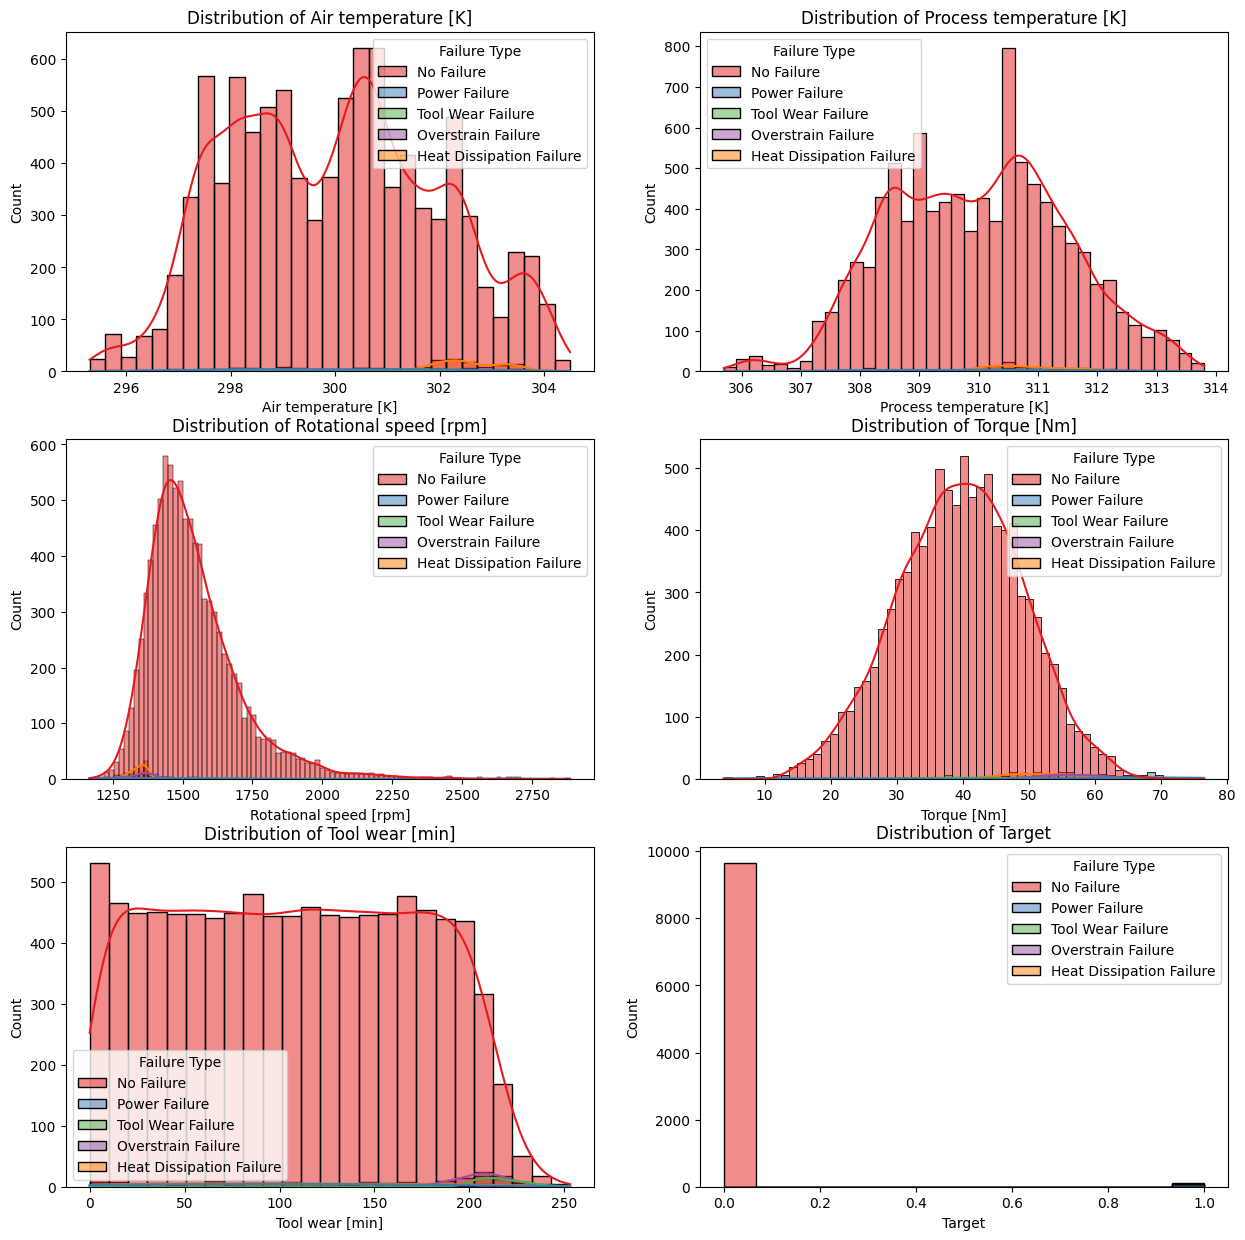

In [36]:
num_cols = df.select_dtypes(exclude='O').columns.tolist()
plt.figure(figsize=(15,15))
for i, col in enumerate(num_cols):
    plt.subplot(3,2,i+1)
    sns.histplot(data = df, x=col, hue='Failure Type', kde=True, palette='Set1')
    plt.title(f'Distribution of {col}')

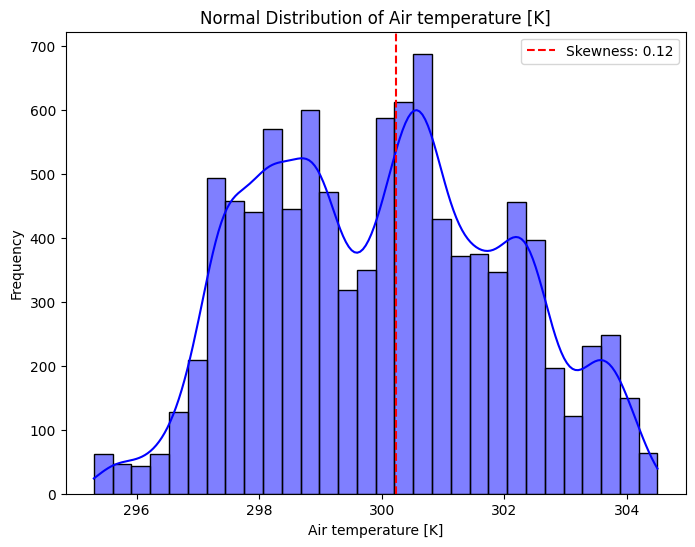

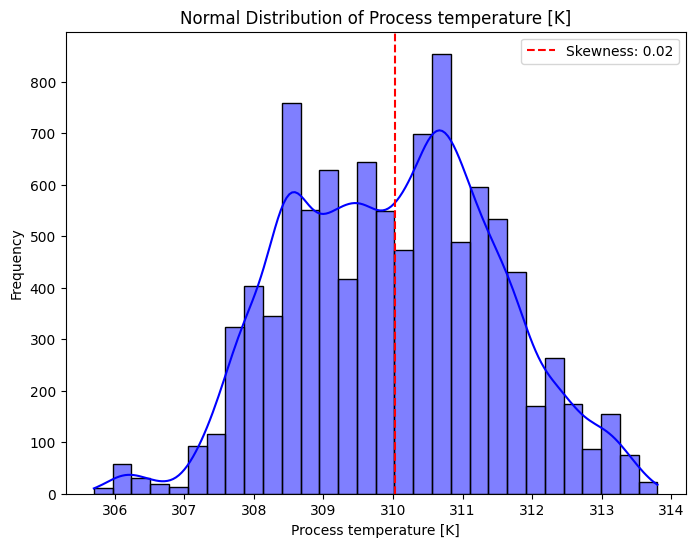

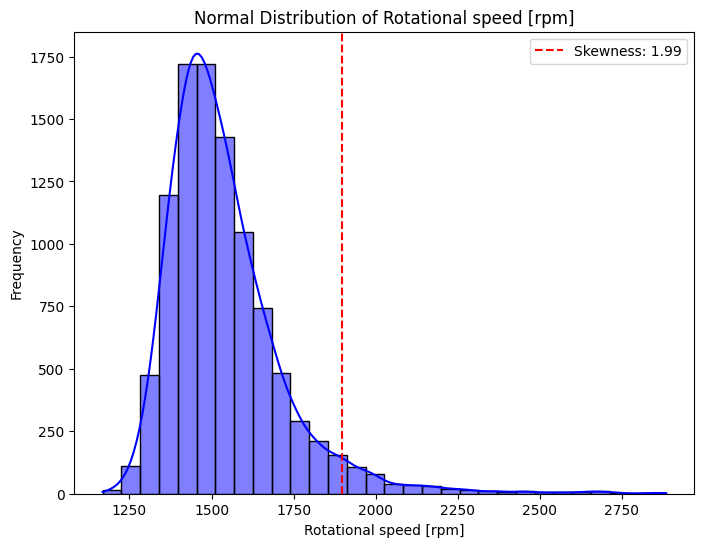

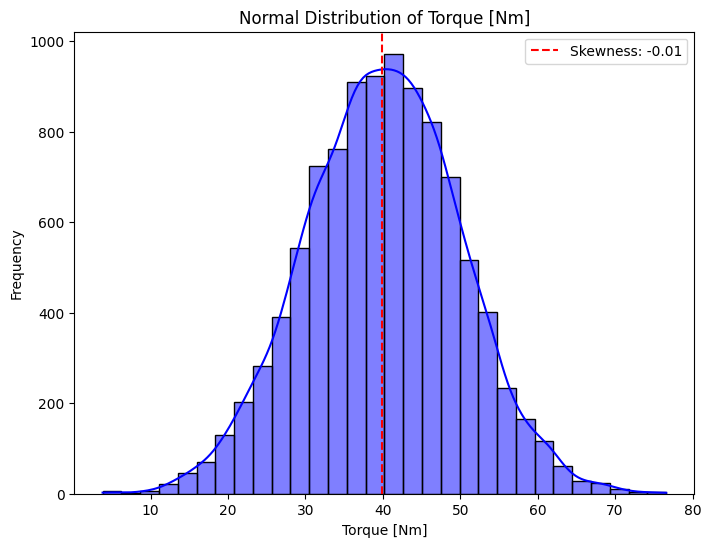

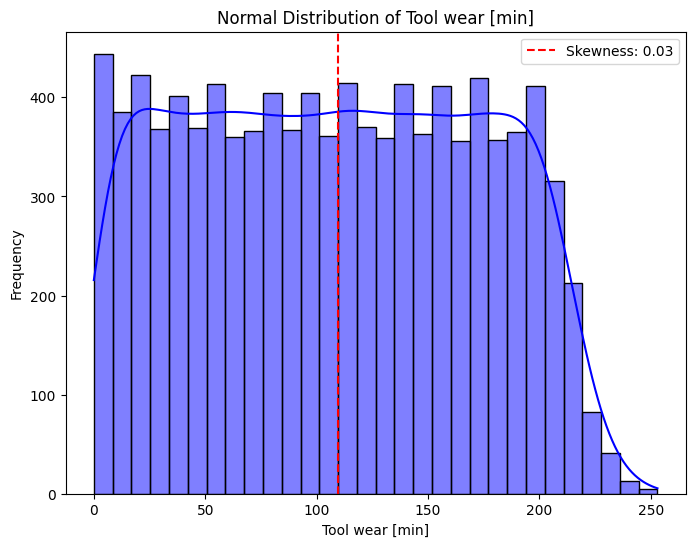

In [37]:
from scipy.stats import skew

# Extract continuous features
continuous_features = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

# Generate normal distribution plots for each continuous feature
for feature in continuous_features:
    # Generate synthetic data for the feature (replace df[feature] with your actual data)
    data = df[feature]

    # Calculate skewness
    data_skewness = skew(data)

    # Create figure and axes
    plt.figure(figsize=(8, 6))

    # Plot histogram with kernel density estimation
    sns.histplot(data, kde=True, color='blue', bins=30)

    # Add vertical line to indicate skewness
    plt.axvline(x=data.mean() + data_skewness * data.std(), color='red', linestyle='--', label=f'Skewness: {data_skewness:.2f}')

    # Add labels and title
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.title(f'Normal Distribution of {feature}')
    plt.legend()

    # Show plot
    plt.show()

## Pairplot visualization

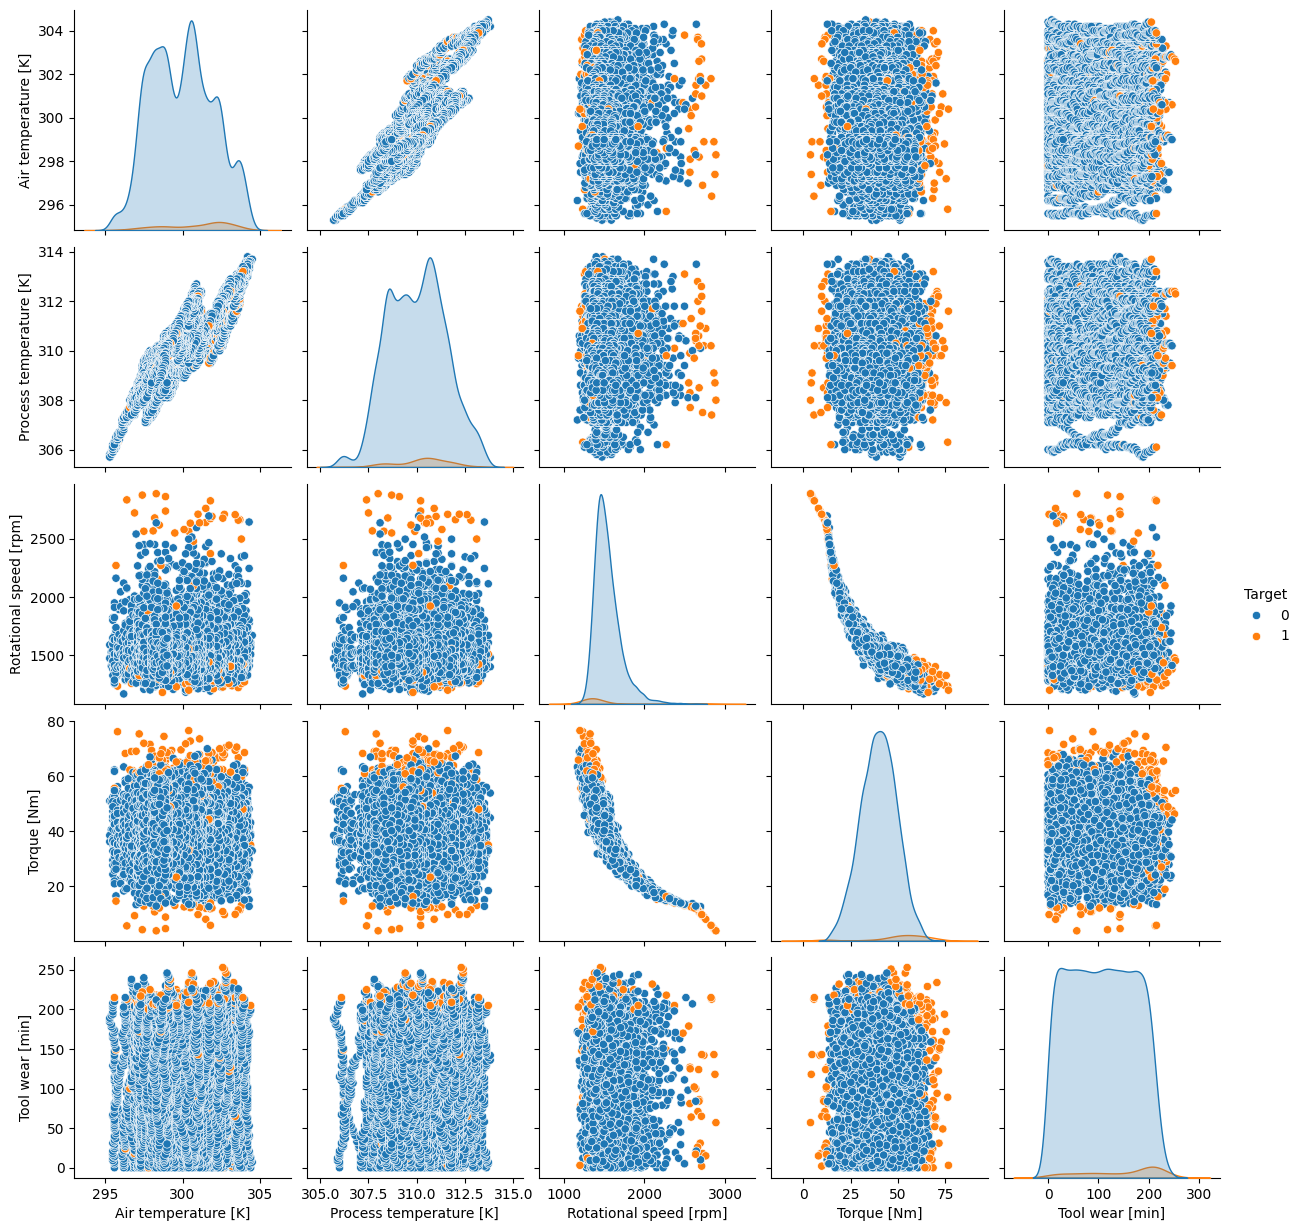

In [38]:
sns.pairplot(df, hue='Target')
plt.show()

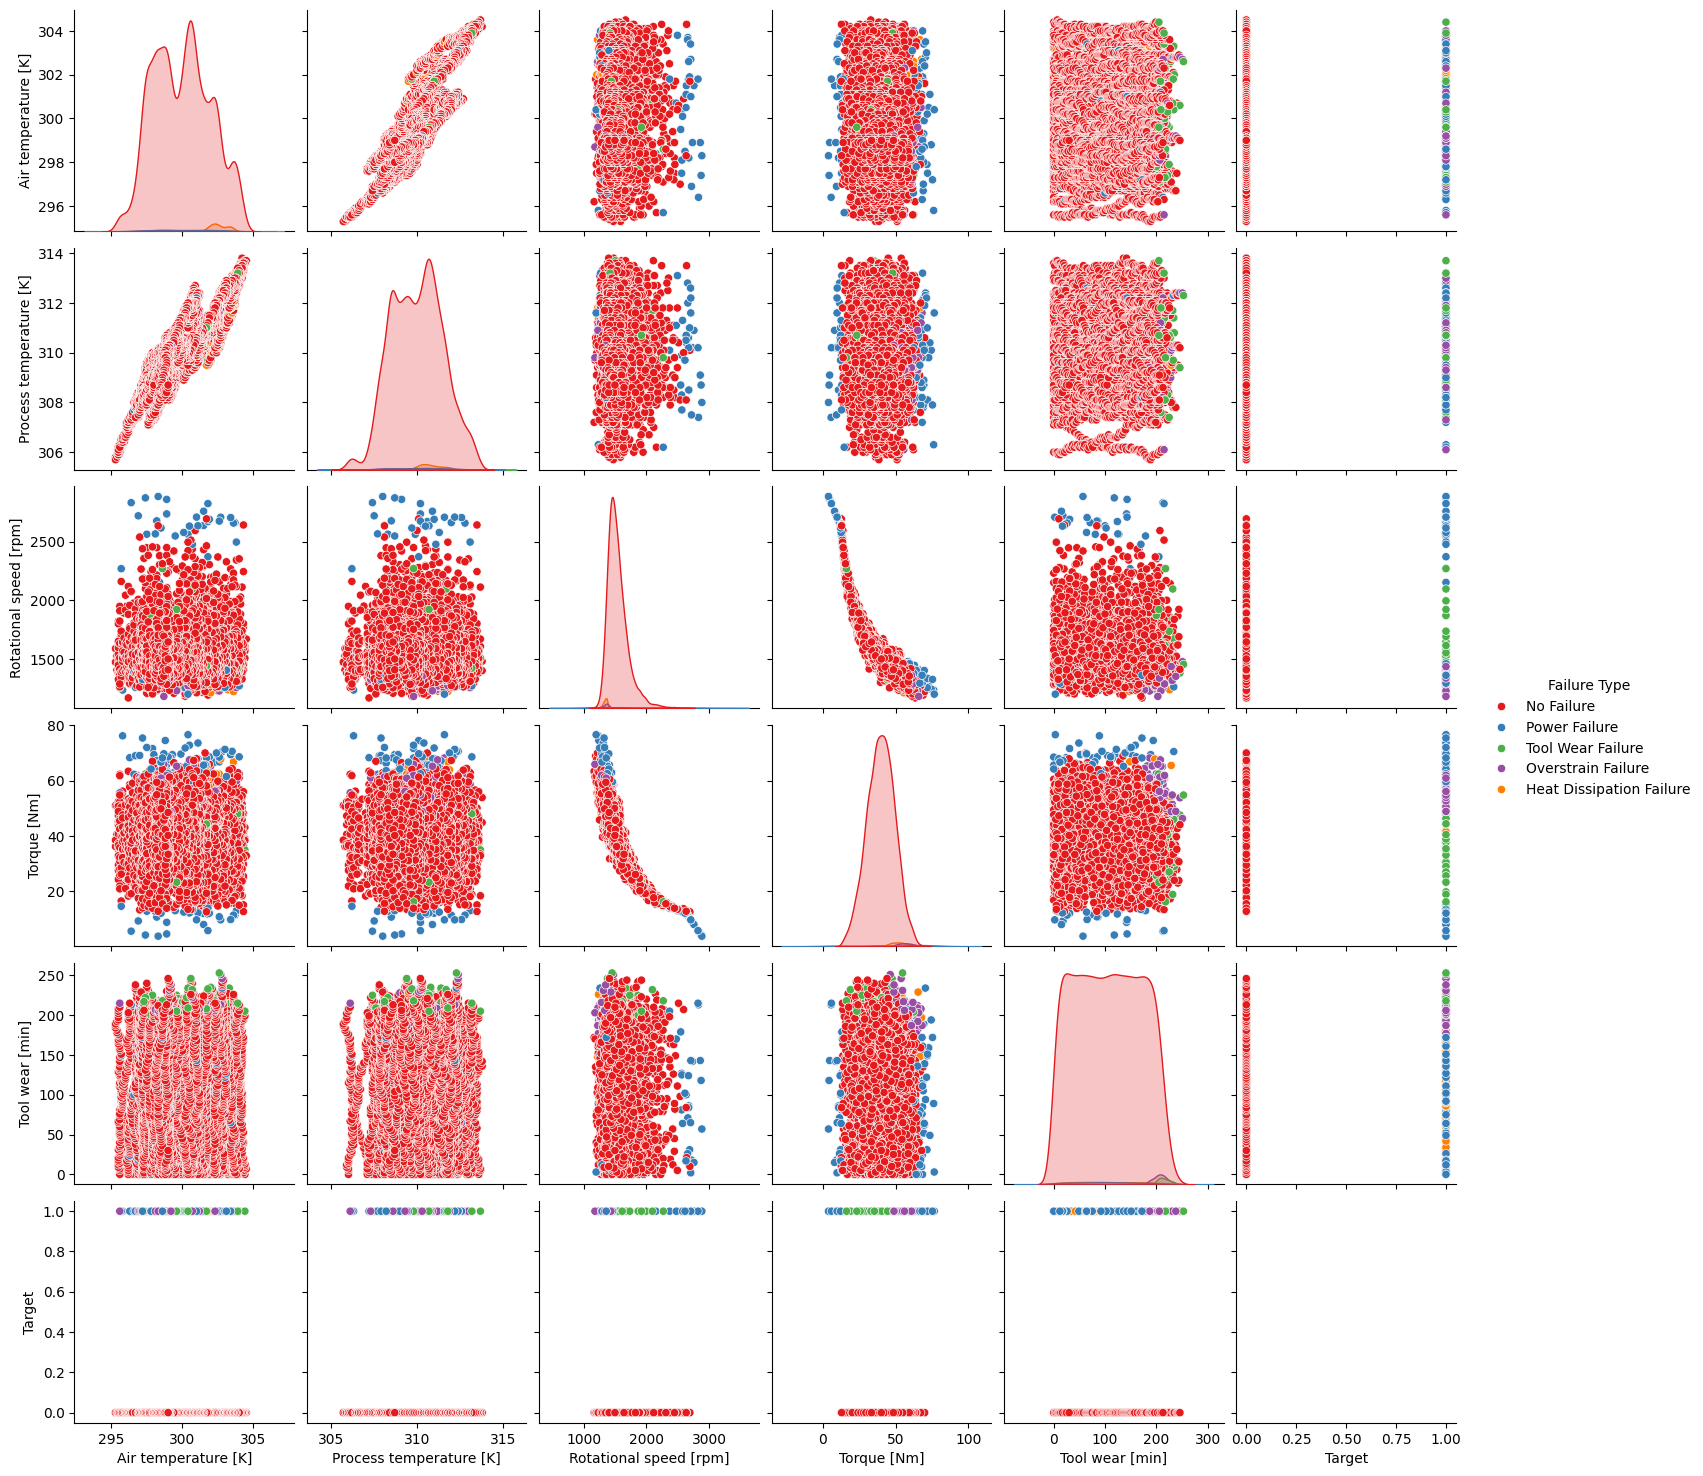

In [39]:
sns.pairplot(df, hue='Failure Type', palette="Set1")
plt.show()

## Value counts for categorical columns

In [40]:
for col in cat_cols:
    print(df[col].value_counts())

Type
L    5984
M    2991
H     998
Name: count, dtype: int64
Failure Type
No Failure                  9643
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Name: count, dtype: int64


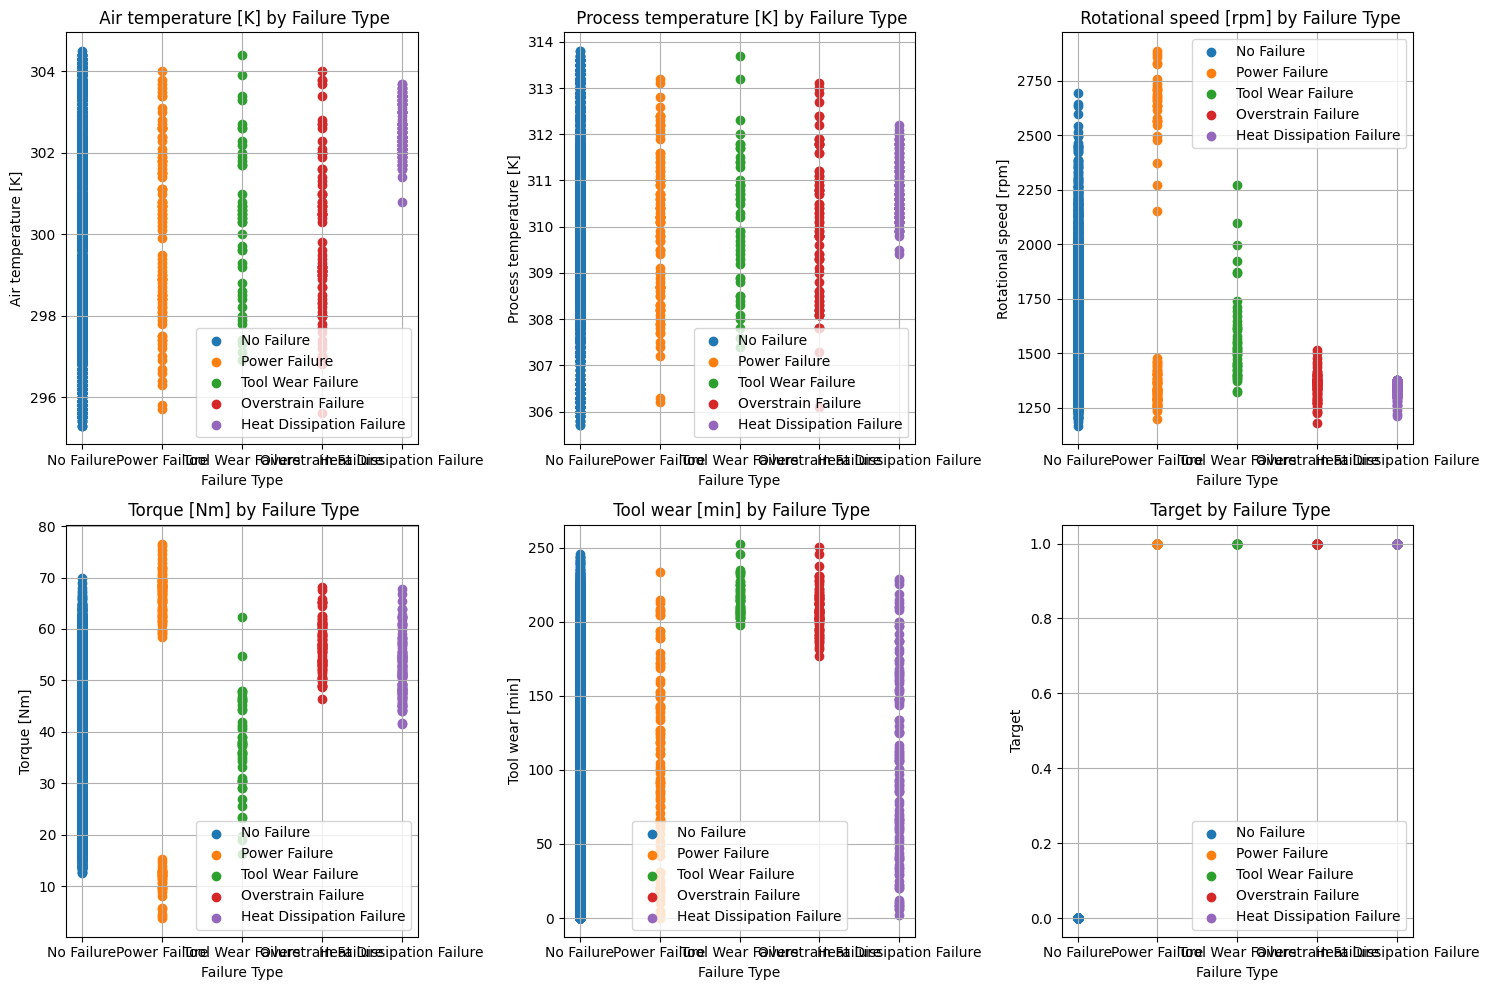

In [41]:
# Variables
categorical_var = 'Failure Type'
continuous_vars = df.select_dtypes(include=['float64', 'int64']).columns.tolist()

# Subplots
num_vars = len(continuous_vars)
num_cols = 3  # plots per line
num_rows = (num_vars + num_cols - 1) // num_cols  # neccesary number of rows

fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, 5 * num_rows))
axes = axes.flatten()  # flatting the matrix axis

# Plot per variable
for i, var in enumerate(continuous_vars):
    for failure_type in df[categorical_var].unique():
        subset = df[df[categorical_var] == failure_type]
        axes[i].scatter(subset[categorical_var], subset[var], label=failure_type)

    axes[i].set_title(f' {var} by {categorical_var}')
    axes[i].set_xlabel(categorical_var)
    axes[i].set_ylabel(var)
    axes[i].legend()
    axes[i].grid()

# Deleting empty axis if there are less varibles than subplots
for j in range(i + 1, num_rows * num_cols):
    fig.delaxes(axes[j])

plt.tight_layout()  # Adjustment of layout not to shorten the tags
plt.show()

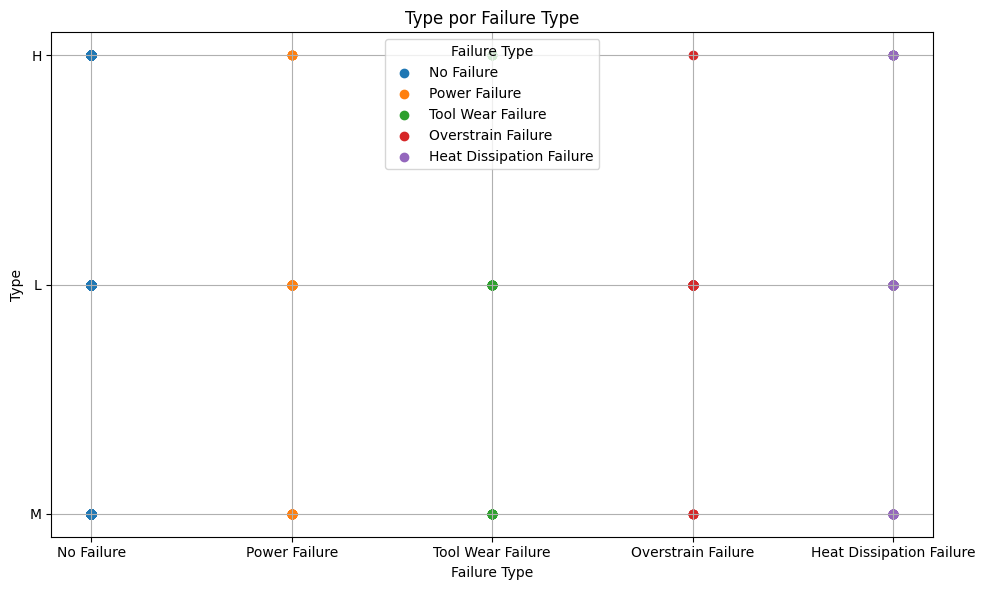

Failure Type  Heat Dissipation Failure  No Failure  Overstrain Failure  \
Type                                                                     
H                                    8         978                   1   
L                                   74        5753                  73   
M                                   30        2912                   4   
Total                              112        9643                  78   

Failure Type  Power Failure  Tool Wear Failure  Total  
Type                                                   
H                         5                  6    998  
L                        59                 25   5984  
M                        31                 14   2991  
Total                    95                 45   9973  


In [42]:
# Identify the categorical variable and the variable to plot
categorical_var_x = 'Failure Type'
categorical_var_y = 'Type'
# Create a figure for a single plot
plt.figure(figsize=(10, 6))

# Graphing
for failure_type in df[categorical_var_x].unique():
    subset = df[df[categorical_var_x] == failure_type]
    plt.scatter(subset[categorical_var_x], subset[categorical_var_y], label=failure_type)

# Graph configuration
plt.title(f'{categorical_var_y} por {categorical_var_x}')
plt.xlabel(categorical_var_x)
plt.ylabel(categorical_var_y)
plt.legend(title=categorical_var_x)
plt.grid()

plt.tight_layout()
plt.show()

# Create a contingency table
contingency_table = pd.crosstab(df['Type'], df['Failure Type'], margins=True, margins_name="Total")

# Show the table
print(contingency_table)

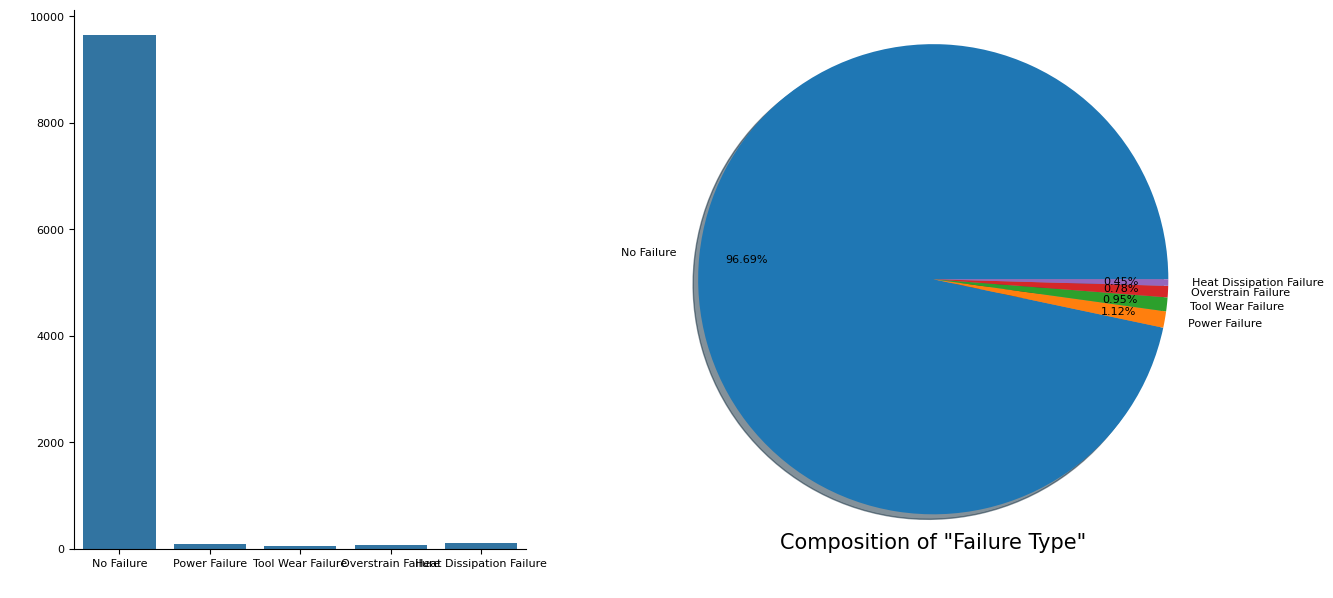

In [43]:
# defining the target variable
df['Failure Type'].value_counts()
# checking the target
plt.figure(figsize=(14,7))
# barplot
ax1 = plt.subplot(1,2,1)
cp = sns.countplot(x=df["Failure Type"])
ax1.set_xlabel(" ")
ax1.set_ylabel(" ")
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
sns.despine(top=True, right=True)
# pieplot
ax2 = plt.subplot(1,2,2)
plt.pie(df["Failure Type"].value_counts(),
        labels=list(df["Failure Type"].unique()),
        autopct='%1.2f%%',
        pctdistance=0.8,
        shadow=True,
        radius=1.3,
        textprops={'fontsize':8}
       )
ax2.set_xlabel(" ")
plt.xlabel('Composition of "Failure Type"', fontsize=15, labelpad=20)
plt.subplots_adjust(wspace=0.4)
plt.show()

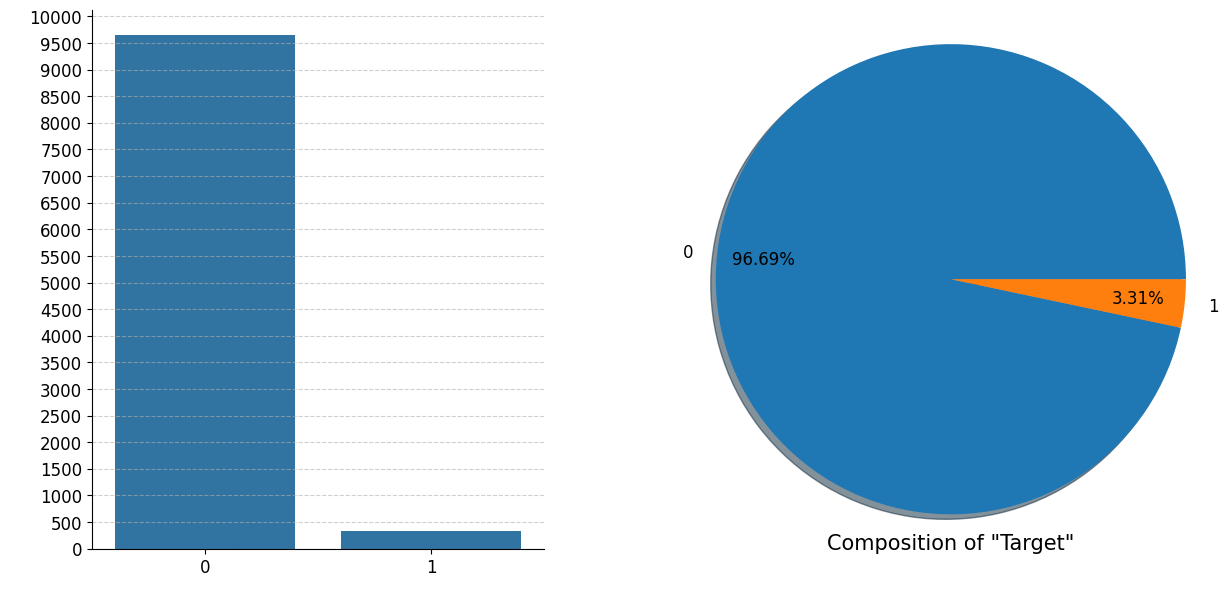

In [44]:
# defining the target variable
df['Target'].value_counts()
# checking the target
plt.figure(figsize=(14,7))
# barplot
ax1 = plt.subplot(1,2,1)
cp = sns.countplot(x=df["Target"])
ax1.set_xlabel(" ")
ax1.set_ylabel(" ")
plt.xticks(fontsize=12)
plt.yticks(np.arange(0, 10001, 500), fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.6)
sns.despine(top=True, right=True)
# pieplot
ax2 = plt.subplot(1,2,2)
plt.pie(df["Target"].value_counts(),
        labels=list(df["Target"].unique()),
        autopct='%1.2f%%',
        pctdistance=0.8,
        shadow=True,
        radius=1.3,
        textprops={'fontsize':12}
       )
ax2.set_xlabel(" ")
plt.xlabel('Composition of "Target"', fontsize=15, labelpad=20)
plt.subplots_adjust(wspace=0.4)
plt.show()

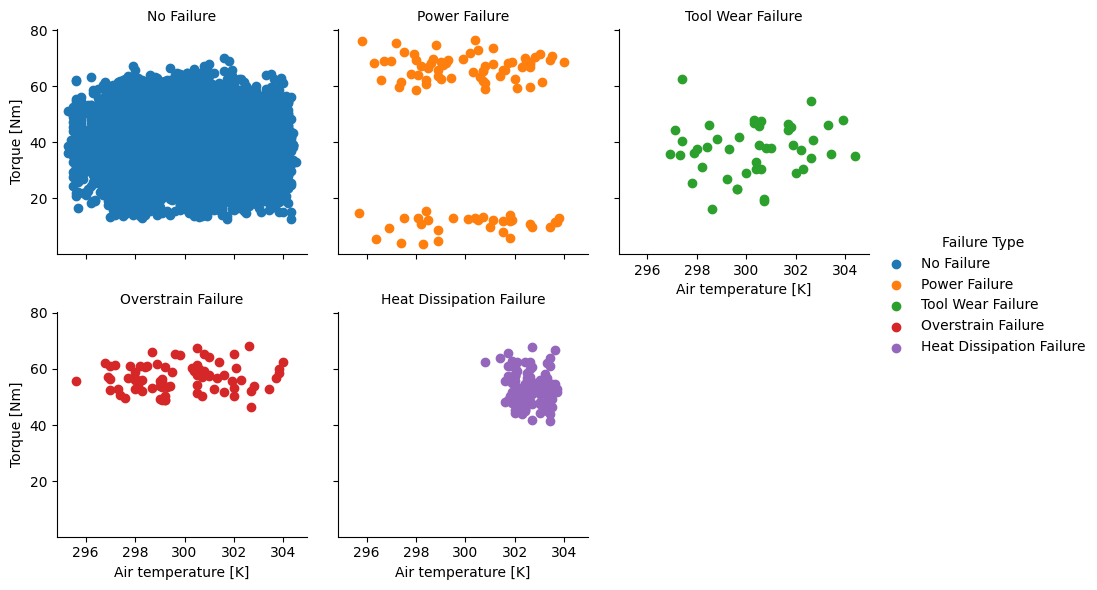

In [45]:
# Create a FacetGrid with seaborn
g = sns.FacetGrid(df, col="Failure Type", hue="Failure Type", col_wrap=3)
# Map a scatter plot to each facet
g.map(plt.scatter, "Air temperature [K]", "Torque [Nm]")
# Add a title to each facet
g.set_titles(col_template="{col_name}")
# Add legend
g.add_legend()
# Show the plot
plt.show()

## Encoding and mapping categorical variables

In [46]:
# Importing labelEncoder library
from sklearn.preprocessing import LabelEncoder

# Columns to encode
columns_to_encode = ['Type', 'Failure Type']

# Dictionary to hold the mappings for each column
label_encoders = {}
mappings = {}

# Apply LabelEncoder to each column
for column in columns_to_encode:
    encoder = LabelEncoder()
    df[column] = encoder.fit_transform(df[column])
    label_encoders[column] = encoder
    mappings[column] = dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))

    # Display the mappings
for column, mapping in mappings.items():
    print(f'Mapping for {column}: {mapping}')

Mapping for Type: {'H': np.int64(0), 'L': np.int64(1), 'M': np.int64(2)}
Mapping for Failure Type: {'Heat Dissipation Failure': np.int64(0), 'No Failure': np.int64(1), 'Overstrain Failure': np.int64(2), 'Power Failure': np.int64(3), 'Tool Wear Failure': np.int64(4)}


In [47]:
# Rename the variables
df.rename(columns={'Air temperature [K]': 'Air_temperature', 'Rotational speed [rpm]': 'Rotational_speed', 'Torque [Nm]': 'Torque','Tool wear [min]': 'Tool_wear','Failure Type': 'Failure_Type', 'Process temperature [K]': 'Process_temperature'}, inplace=True)

In [48]:
# Define features (X) and target variable (y)
X = df.drop(['Target', 'Failure_Type'], axis=1)
y = df['Target']

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [49]:
# Models to evaluate
models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "GradientBoosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42),
    "Logistic Regressor": LogisticRegression(max_iter=500),
    "SVM": SVC(probability=True),
    "Nearest Neighbors": KNeighborsClassifier(),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric="logloss"),
    "Tree Decision": DecisionTreeClassifier()
}

# Define hyperparameters for each model
param_grid = {
    "Random Forest": {
        "n_estimators": [50, 100, 200],
        "max_depth": [None, 10, 20],
        "min_samples_split": [2, 5, 10]
    },
    "GradientBoosting": {
        "n_estimators": [50, 100, 200],
        "learning_rate": [0.05, 0.1, 0.2],
        "max_depth": [3, 5, 10]
    },
    "Logistic Regressor": {
        "C": [0.1, 1, 10],
        "solver": ["liblinear", "lbfgs"]
    },
    "SVM": {
        "C": [0.1, 1, 10],
        "kernel": ["linear", "rbf"]
    },
    "Nearest Neighbors": {
        "n_neighbors": [3, 5, 10],
        "weights": ["uniform", "distance"]
    },
    "XGBoost": {
        "n_estimators": [50, 100, 200],
        "learning_rate": [0.05, 0.1, 0.2],
        "max_depth": [3, 5, 10]
    },
    "Tree Decision": {
        "max_depth": [None, 5, 10],
        "min_samples_split": [2, 5, 10]
    }
}

# Perform GridSearch for each model
best_models = {}

for name, model in models.items():
    if name in param_grid:
        grid_search = GridSearchCV(model, param_grid[name], cv=3, scoring="accuracy", n_jobs=-1)
        grid_search.fit(X, y)
        best_models[name] = grid_search.best_estimator_

        print(f"\n🔹 Best configuration for {name}:")
        print(grid_search.best_params_)
    else:
        best_models[name] = model


🔹 Best configuration for Random Forest:
{'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 50}

🔹 Best configuration for GradientBoosting:
{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 50}

🔹 Best configuration for Logistic Regressor:
{'C': 0.1, 'solver': 'liblinear'}

🔹 Best configuration for SVM:
{'C': 10, 'kernel': 'rbf'}

🔹 Best configuration for Nearest Neighbors:
{'n_neighbors': 10, 'weights': 'distance'}

🔹 Best configuration for XGBoost:
{'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 200}

🔹 Best configuration for Tree Decision:
{'max_depth': 10, 'min_samples_split': 10}


Distribution of y_train after SMOTE: Counter({0: 7707, 1: 7707})
Distribution of y_test (without SMOTE): Counter({0: 1936, 1: 59})


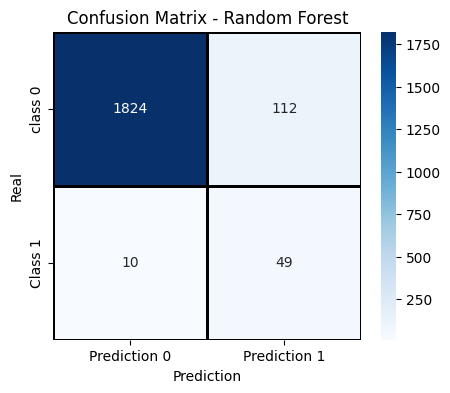

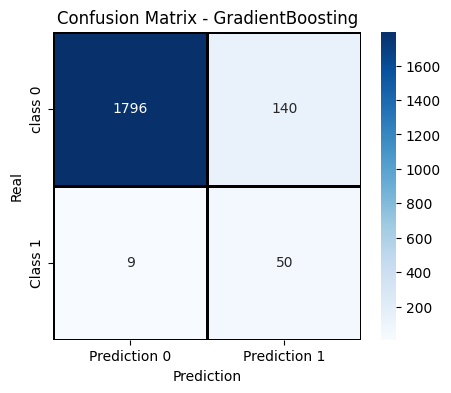

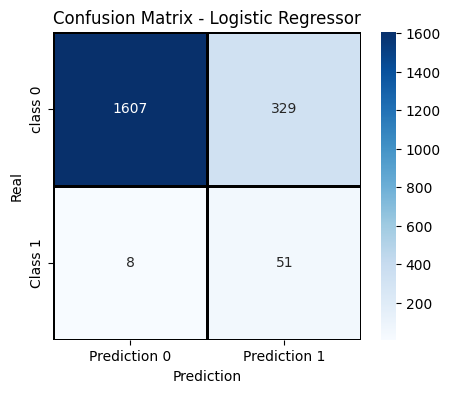

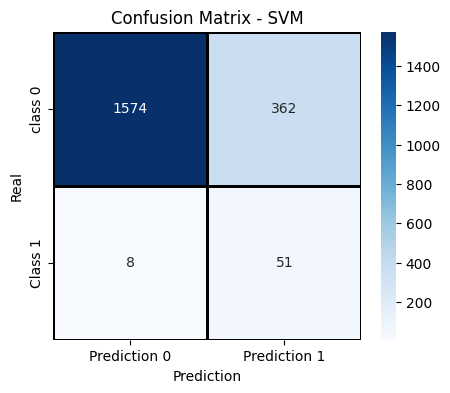

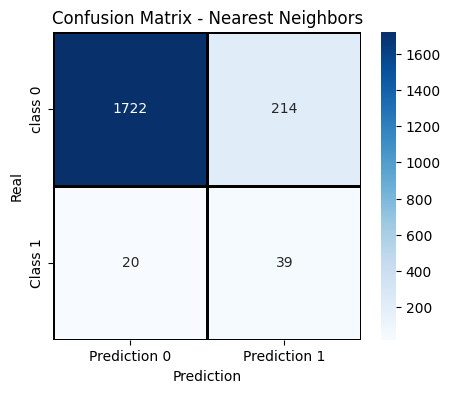

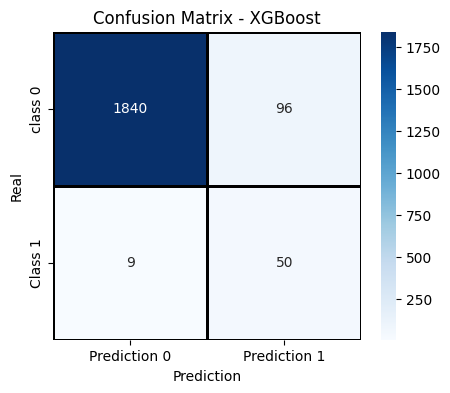

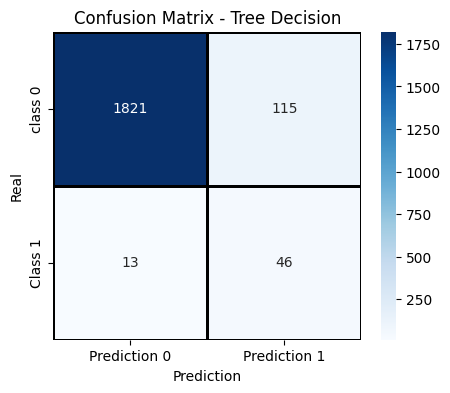

Distribution of y_train after SMOTE: Counter({0: 7710, 1: 7710})
Distribution of y_test (without SMOTE): Counter({0: 1933, 1: 62})


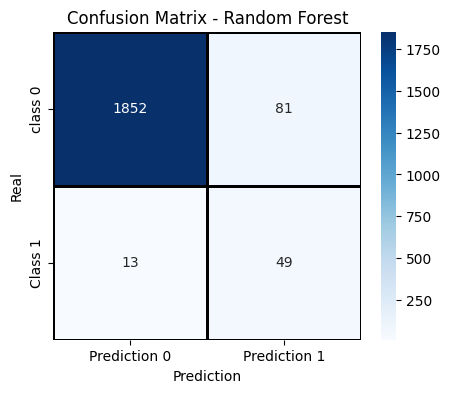

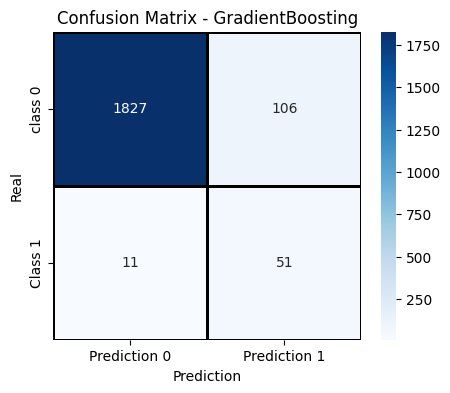

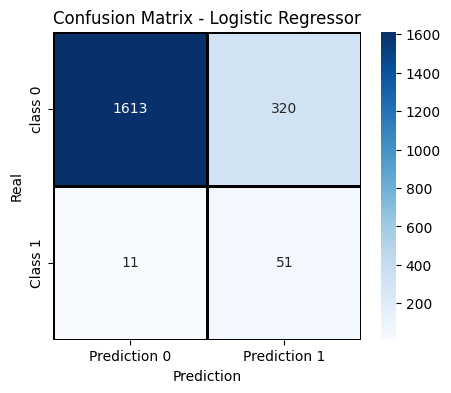

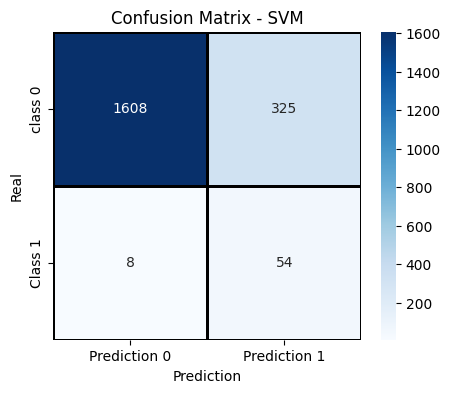

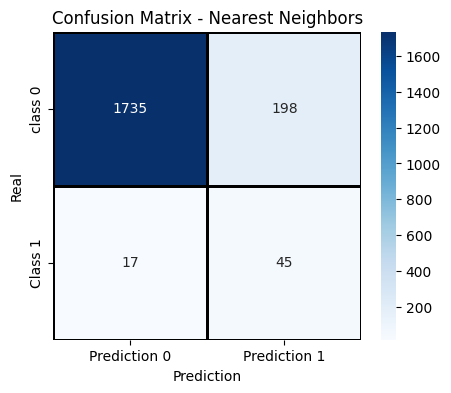

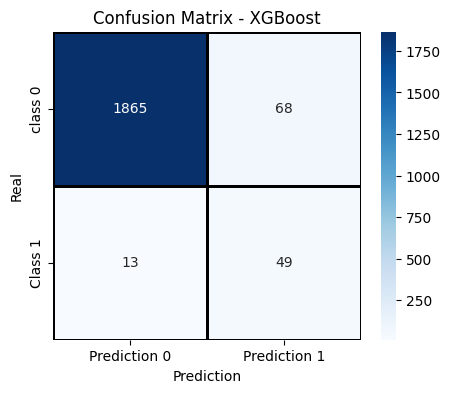

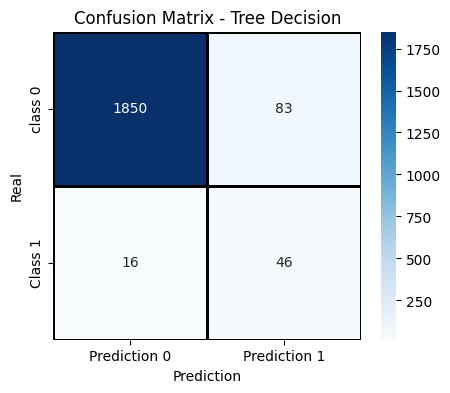

Distribution of y_train after SMOTE: Counter({0: 7711, 1: 7711})
Distribution of y_test (without SMOTE): Counter({0: 1932, 1: 63})


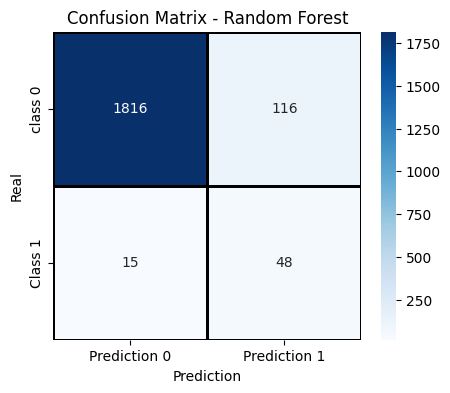

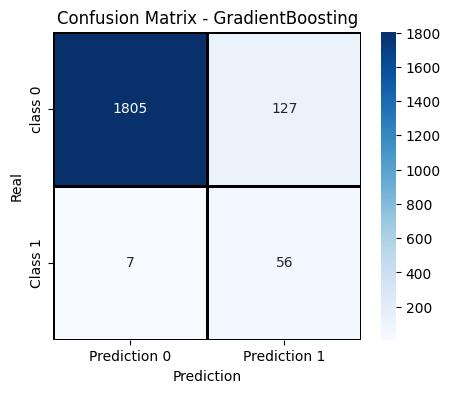

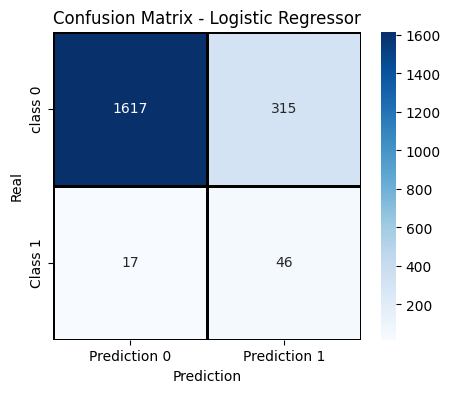

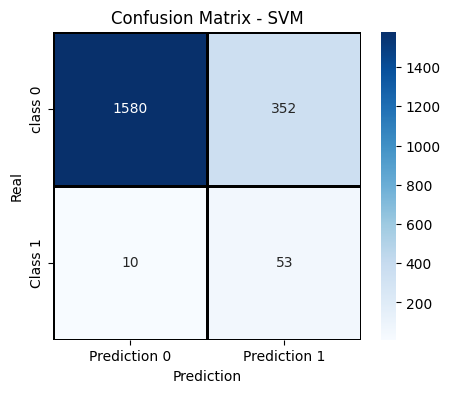

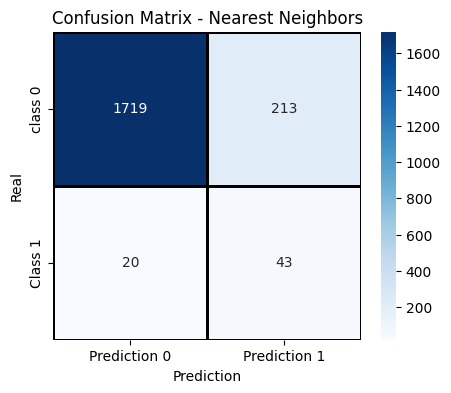

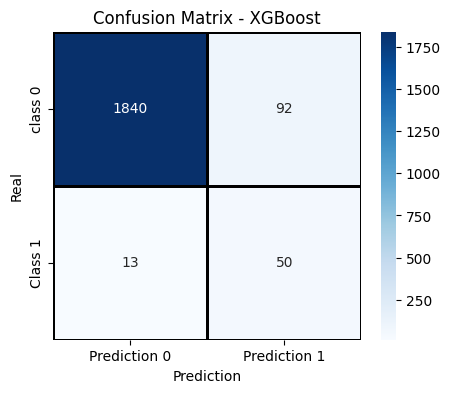

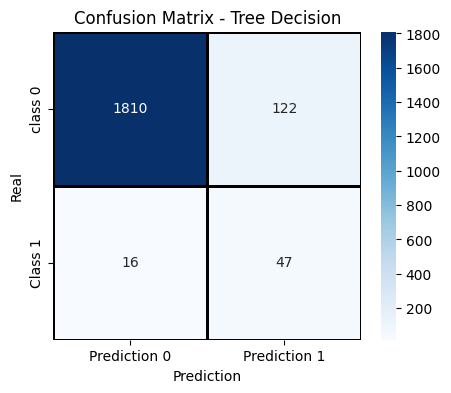

Distribution of y_train after SMOTE: Counter({0: 7711, 1: 7711})
Distribution of y_test (without SMOTE): Counter({0: 1932, 1: 62})


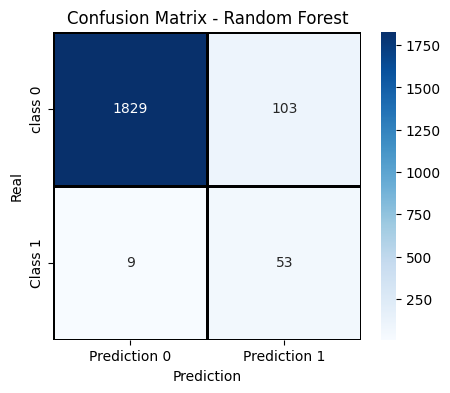

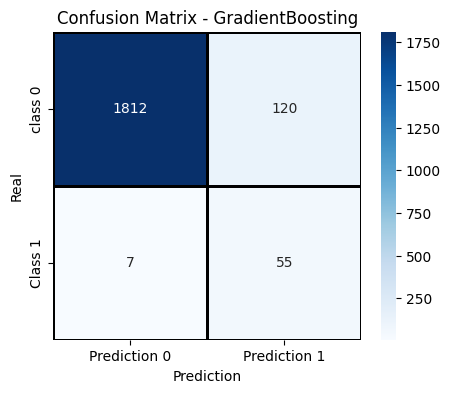

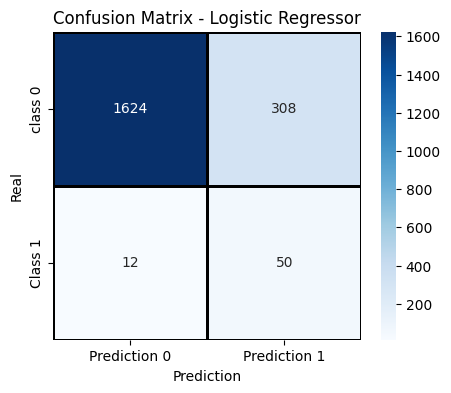

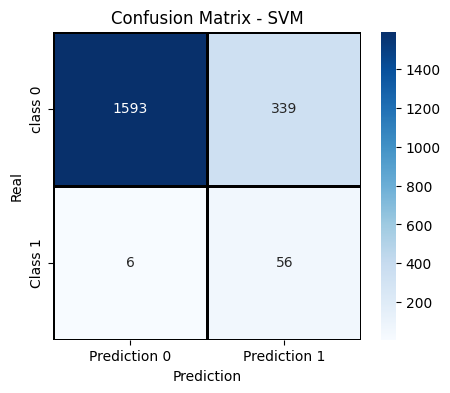

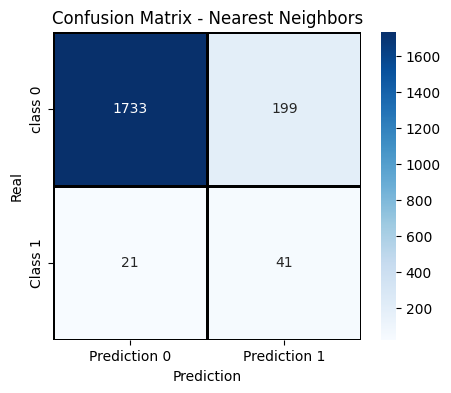

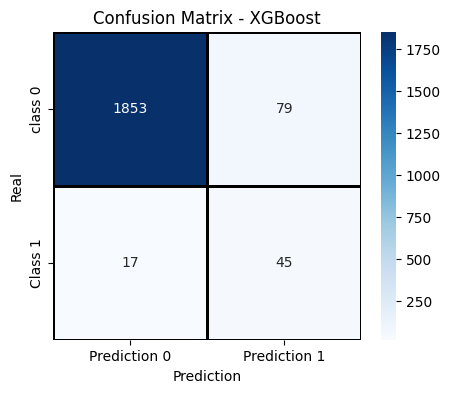

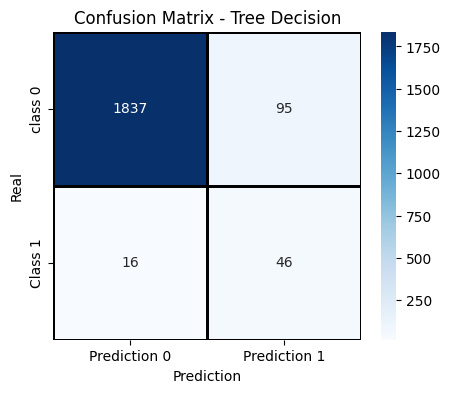

Distribution of y_train after SMOTE: Counter({0: 7733, 1: 7733})
Distribution of y_test (without SMOTE): Counter({0: 1910, 1: 84})


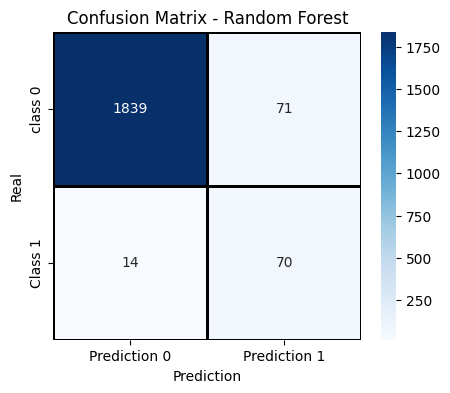

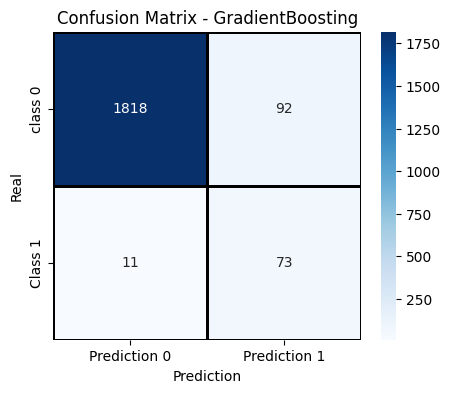

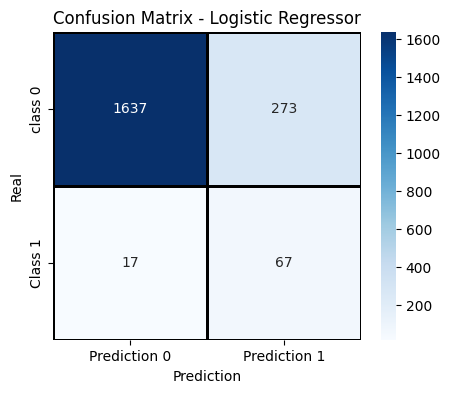

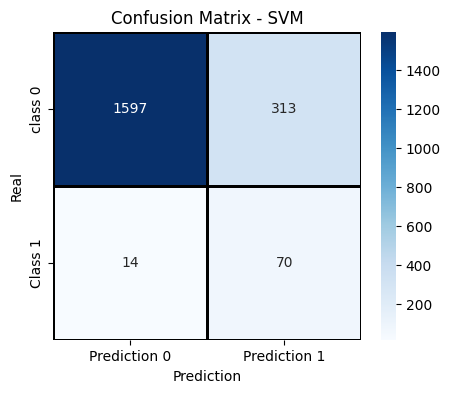

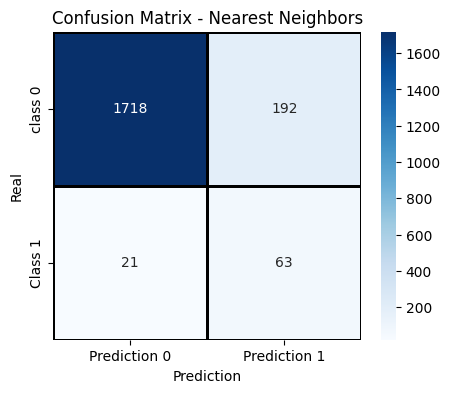

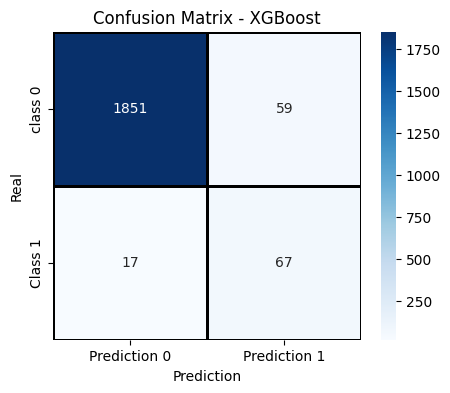

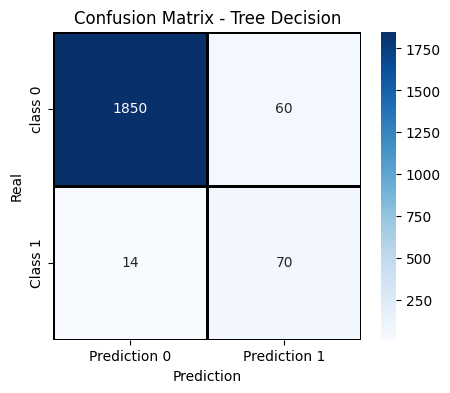


🔹 Random Forest:
  Accuracy: 0.9455
  Precision: 0.3620
  Recall (Sensibilidad): 0.8142
  F1-score: 0.4974
  Specificity: 0.9499
  AUC-ROC: 0.9721

🔹 GradientBoosting:
  Accuracy: 0.9368
  Precision: 0.3301
  Recall (Sensibilidad): 0.8630
  F1-score: 0.4746
  Specificity: 0.9394
  AUC-ROC: 0.9736

🔹 Logistic Regressor:
  Accuracy: 0.8386
  Precision: 0.1472
  Recall (Sensibilidad): 0.8042
  F1-score: 0.2478
  Specificity: 0.8398
  AUC-ROC: 0.9019

🔹 SVM:
  Accuracy: 0.8258
  Precision: 0.1443
  Recall (Sensibilidad): 0.8626
  F1-score: 0.2465
  Specificity: 0.8247
  AUC-ROC: 0.9273

🔹 Nearest Neighbors:
  Accuracy: 0.8882
  Precision: 0.1850
  Recall (Sensibilidad): 0.6961
  F1-score: 0.2916
  Specificity: 0.8947
  AUC-ROC: 0.8804

🔹 XGBoost:
  Accuracy: 0.9536
  Precision: 0.4016
  Recall (Sensibilidad): 0.7910
  F1-score: 0.5290
  Specificity: 0.9592
  AUC-ROC: 0.9773

🔹 Tree Decision:
  Accuracy: 0.9449
  Precision: 0.3570
  Recall (Sensibilidad): 0.7686
  F1-score: 0.4825
  Specif

In [50]:
# Configure K-Fold Cross Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Models to evaluate
models = {
    "Random Forest": RandomForestClassifier(max_depth= 10, min_samples_split= 5, n_estimators= 50, random_state=42),
    "GradientBoosting": GradientBoostingClassifier(n_estimators=50, learning_rate=0.05, max_depth=5, random_state=42),
    "Logistic Regressor": LogisticRegression(max_iter=500, C= 0.1, solver="liblinear"),
    "SVM": SVC(probability=True, C= 10, kernel="rbf"),
    "Nearest Neighbors": KNeighborsClassifier(n_neighbors= 10, weights="distance"),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric="logloss", learning_rate= 0.05, max_depth= 10, n_estimators= 50),
    "Tree Decision": DecisionTreeClassifier(max_depth= 10, min_samples_split= 10)
}

# Dictionary to store results
results = {name: {"accuracy": [], "precision": [], "recall": [], "f1": [], "specificity": [], "auc_roc": []}
           for name in models.keys()}

# Cross validation with SMOTE
for train_index, test_index in kf.split(X, y):
    # Split the data into each fold
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Apply SMOTE to the training set
    smote = SMOTE(sampling_strategy=1.0, random_state=42)
    X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

    # View distribution after SMOTE
    print("Distribution of y_train after SMOTE:", Counter(y_train_resampled))
    print("Distribution of y_test (without SMOTE):", Counter(y_test))

    for name, model in models.items():
        model.fit(X_train_resampled, y_train_resampled)
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None

        # calculate metrics
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred).flatten()
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        auc_roc = roc_auc_score(y_test, y_prob) if y_prob is not None else 0

        results[name]["accuracy"].append(accuracy_score(y_test, y_pred))
        results[name]["precision"].append(precision_score(y_test, y_pred))
        results[name]["recall"].append(recall_score(y_test, y_pred))
        results[name]["f1"].append(f1_score(y_test, y_pred))
        results[name]["specificity"].append(specificity)
        results[name]["auc_roc"].append(auc_roc)

       # Confusion Matrix
        cm = confusion_matrix(y_test, y_pred, labels=[0,1])
        cm_df = pd.DataFrame(cm, index=['class 0', 'Class 1'], columns=['Prediction 0', 'Prediction 1'])

        plt.figure(figsize=(5,4))
        sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", linewidths=1, linecolor="black", square=True)
        plt.title(f"Confusion Matrix - {name}")
        plt.xlabel("Prediction")
        plt.ylabel("Real")
        plt.show()

# Show average results
for name in models.keys():
    print(f"\n🔹 {name}:")
    print(f"  Accuracy: {np.mean(results[name]['accuracy']):.4f}")
    print(f"  Precision: {np.mean(results[name]['precision']):.4f}")
    print(f"  Recall (Sensibilidad): {np.mean(results[name]['recall']):.4f}")
    print(f"  F1-score: {np.mean(results[name]['f1']):.4f}")
    print(f"  Specificity: {np.mean(results[name]['specificity']):.4f}")
    print(f"  AUC-ROC: {np.mean(results[name]['auc_roc']):.4f}")

In [ ]:
## ==========================================
## 7. MODEL TRAINING & PREDICTION ON NEW DATA
## ==========================================

# 1. Entrenar el modelo final elegido con todo el conjunto de datos (X e y)
# Usamos SMOTE para balancear antes de entrenar el modelo final
smote_final = SMOTE(sampling_strategy=1.0, random_state=42)
X_resampled, y_resampled = smote_final.fit_resample(X, y)

# Seleccionamos el mejor modelo según las métricas (ej. Random Forest)
final_model = RandomForestClassifier(
    max_depth=10,
    min_samples_split=5,
    n_estimators=50,
    random_state=42
)

# Ajustar el modelo final
final_model.fit(X_resampled, y_resampled)
print("✅ Modelo final entrenado exitosamente con datos balanceados.")

# ------------------------------------------
# 2. Creación de Datos Nuevos de Prueba
# ------------------------------------------
# Supongamos que recibimos lecturas de 3 máquinas distintas en tiempo real
# NOTA: 'Type' debe estar codificado con el mismo LabelEncoder (ej. L=0, M=1, H=2)

nuevos_datos = pd.DataFrame({
    'Type': [0, 1, 2],                      # 0=L, 1=M, 2=H
    'Air_temperature': [298.1, 302.5, 300.0],
    'Process_temperature': [308.6, 311.2, 310.5],
    'Rotational_speed': [1500, 1350, 2800], # Caso 3 tiene RPM muy alto y alto torque (posible falla)
    'Torque': [40.0, 55.0, 65.0],
    'Tool_wear': [10, 180, 220]             # Caso 3 tiene desgaste muy alto
})

# ------------------------------------------
# 3. Realizar las Predicciones
# ------------------------------------------
# Predicción de clase (0 = Sin Falla, 1 = Con Falla)
predicciones = final_model.predict(nuevos_datos)

# Probabilidad de falla (número entre 0 y 1)
probabilidades = final_model.predict_proba(nuevos_datos)[:, 1]

# ------------------------------------------
# 4. Mostrar Resultados de Forma Clara
# ------------------------------------------
df_resultados = nuevos_datos.copy()

# Mapear el 'Type' codificado de vuelta a su letra original para facilitar lectura
encoder_type = label_encoders['Type']
df_resultados['Type_Original'] = encoder_type.inverse_transform(df_resultados['Type'])

# Agregar resultados
df_resultados['Prediccion_Target'] = predicciones
df_resultados['Estado_Maquina'] = np.where(predicciones == 1, '⚠️ REQUIERE MANTENIMIENTO', '✅ NORMAL')
df_resultados['Probabilidad_Falla'] = (probabilidades * 100).round(2).astype(str) + '%'

# Reordenar y mostrar columnas relevantes
cols_mostrar = ['Type_Original', 'Air_temperature', 'Process_temperature',
                'Rotational_speed', 'Torque', 'Tool_wear', 'Estado_Maquina', 'Probabilidad_Falla']

print("\n--- RESULTADOS DE MANTENIMIENTO PREDICTIVO PARA NUEVOS EQUIPOS ---")
display(df_resultados[cols_mostrar])

✅ Modelo final entrenado exitosamente con datos balanceados.

--- RESULTADOS DE MANTENIMIENTO PREDICTIVO PARA NUEVOS EQUIPOS ---


,Type_Original,Air_temperature,Process_temperature,Rotational_speed,Torque,Tool_wear,Estado_Maquina,Probabilidad_Falla
0,H,298.1,308.6,1500,40.0,10,✅ NORMAL,0.12%
1,L,302.5,311.2,1350,55.0,180,⚠️ REQUIERE MANTENIMIENTO,94.3%
2,M,300.0,310.5,2800,65.0,220,⚠️ REQUIERE MANTENIMIENTO,58.61%
